<h3><center>Introduction to building a quant pricing library</center></h3>
<h1><center>Building Blocks of the Framework</center></h1>
<h3><center>Gabor Friedmann</center></h3>
<h4><center>7 October, 2026</center></h4>

## What did we learn last time?

<b>Risk-free interest rate</b> ($r$): Annual return of a riskless investment, i.e. the minimum return an investor expects for any investment.

<b>Spot contract</b>: An agreement between two parties (a buyer and a seller) to trade an asset "*immediately*".

Fair value: $ S_t $

The buyer of a contract takes a *Long* position, while the seller of a contract takes a *Short* position.

<b>Forward contract</b>: An agreement between two parties (a buyer and a seller) to trade an underlying asset at a <u>certain price</u> ($K$: strike) on a <u>certain future date</u> ($T$: expiry). This is an <u>obligation</u> to both parties.

Payoff at expiry (LF): $ \;\;\; S_T-K $

<img src="./img/payoff_forward.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

<b>(European) Call option contract</b>: The option buyer has the <u>right</u>, but not the obligation, to <u><b>buy</b></u> an underlying asset at a certain price ($K$: strike) on a certain future date ($T$: expiry). If option is exercised by buyer, the option seller must <u>sell</u> the underlying asset.

Payoff at expiry (LC): $ \;\;\; max\lbrace S_T-K, 0\rbrace $

<img src="./img/payoff_call.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

<b>(European) Put option contract</b>: The option buyer has the <u>right</u>, but not the obligation, to <u><b>sell</b></u> an underlying asset at a certain price ($K$: strike) on a certain future date ($T$: expiry). If option is exercised by the option buyer, the option seller must <u>buy</u> the underlying asset.

Payoff at expiry (LP): $ \;\;\; max\lbrace K-S_T, 0\rbrace $

<img src="./img/payoff_put.jpg" style="margin-left:auto; margin-right:auto; width: 730px;" />

## Pricing under Black-Scholes model assumptions
Spot price: $ S_t $, strike price: $ K $, expiry: $ T $, volatility of underlying: $ \sigma $, risk-free rate: $ r $

<b>Forward (LF)</b>: $ \;\;\; f_t = S_t - Ke^{-r(T-t)} $

<b>Call option (LC)</b>: $ \;\;\; c_t = S_tN(d_1) - Ke^{-r(T-t)}N(d_2) $

<b>Put option (LP)</b>: $ \;\;\; p_t = Ke^{-r(T-t)}N(-d_2) - S_tN(-d_1) $

where $N(\cdot)$ is the standard normal CDF

$ d_1 = \dfrac{1}{\sigma\sqrt{T-t}}\left[ln\left(\dfrac{S_t}{K}\right)+\left(r+\dfrac{\sigma^2}{2}\right)(T-t)\right] \;\;\;\;\;\;\;\;\;\; d_2 = d_1 - \sigma\sqrt{T-t} $

<br>
<b>Put-call parity</b>: $ LF=LC+SP $

$ f_t=c_t-p_t $

## Warm up exercise

Let's price a real life European call option contract on a Google stock using Black-Scholes model.

Data:

* https://finance.yahoo.com/quote/GOOG/options?p=GOOG
* https://www.marketwatch.com/investing/bond/tmubmusd01y

<img src="./img/pricing_example.jpg" style="margin-left:auto; margin-right:auto" />

In [1]:
import numpy as np
from scipy.stats import norm

def black_scholes_european_call(S0: float, K: float, T: float, sigma: float, r: float):
    d1 = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2 = d1 - sigma * T**0.5
    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)
    df = np.exp((-1.0)*r*T)
    return S0 * N_d1 - K * df * N_d2

In [2]:
import pandas as pd

df = pd.read_csv('GOOG.csv', usecols=['Date', 'Close'], index_col='Date')
df['CloseTM1'] = df['Close'].shift(1)
df['LogReturn'] = np.log(df['Close'] / df['CloseTM1'])

daily_log_return_std = np.std(df['LogReturn'], ddof=1)
# Annualization: ~260 weekdays per year
volatility = daily_log_return_std * np.sqrt(260)

print(f'Historical volatility: {round(volatility*100, 2)}%')

Historical volatility: 31.58%


In [3]:
import datetime as dt

today = dt.date(2026, 10, 7)

spot = 344.59
strike = 345
expiry = (dt.date(2027,9,17) - today).days / 365
vol = 0.3158
rate = 0.0445

premium = black_scholes_european_call(spot, strike, expiry, vol, rate)
print(f'Premium: {round(premium, 2)}$')

Premium: 48.46$


## How to build a pricing library?

<b>Goal</b>: Implement a coherent code base that is able to calculate fair value and greeks of various contracts in a generic way.

<b>Requirements</b>:
* Separate market data from pricing code
* Reusability: Avoid code duplication
* Scalability: Should be fairly easy to onboard a new contract or a pricer
* Encapsulation: Bundle related data and funcionalities into a structured unit

<img src="./img/building_blocks_empty.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

<img src="./img/building_blocks_full.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

<img src="./img/contracts.jpg" style="margin-left:auto; margin-right:auto; width: 800px;" />

## Important concepts

<b>Inheritance</b>: Deriving a class (Derived/Child/Sub) from another class (Base/Parent/Super) that share a set of properties and methods.

<b>Abstract Base Class (ABC)</b>: Such a class is not concrete and cannot be instantiated. Instead, it forces derived classes to implement all abstract properties and methods.


<b>Let's build the library!</b>

# Tasks

## MarketData - market_data.py

* Define the necessary market data (spot, volatility, risk-free rate) in MarketData class.


| Risk-free rate |
| :-: |
| 0.05 |


| Underlying | Spot | Volatility |
| :- | :-: | :-: |
| Stock.BLUECHIP_BANK | 130.17 | 0.381 |
| Stock.TIPTOP_SOLUTIONS | 177.32 | 0.320 |


## Market Model - model.py

* Define MarketModel class.
* Define its __init__() method:
    * Take an underlying Stock as input.
    * Store the underlying and the corresponding market data (risk-free rate, spot, volatility).
* Implement calc_df() method which takes a tenor and returns the corresponding discount factor.


## Contract - contract.py

* Implement payoff() methods in derived classes
* Make it compulsory to implement these methods for future enhancements

## Pricer - pricer.py

* Implement calc_fair_value() method in EuropeanAnalyticPricer.


## Test - test_pricer.py

* Create put-call parity test for fair value and all greeks using various underlying, strike, expiry.

# Assignments - Digital options

Create a new folder under <b>QuantCourseBP\homeworks</b> and copy over the content of this lecture's solution folder to start with.

1. Get familiar with digital options and implement EuropeanDigitalContract and EuropeanDigitalAnalyticPricer (fair value and greeks) in the library. Implement unit test for fair value using pytest. **(12 points)**
2. Get familiar with bull spread options and by utilizing EuropeanDigitalAnalyticPricer and EuropeanAnalyticPricer, create a figure to visualize that a digital call option can be thought of as a limit of bull spread call options. **(8 points)**

In [4]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from enum import *
from pricer import *

QuantCourseBP 7d165ec7c4cc50b151e51e6c36bbd898a31b115b*


In [5]:
Stock.BLUECHIP_BANK


<Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>

In [6]:
MarketData.risk_free_rate

0.05

In [7]:
MarketData.spot


{<Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>: 130.17,
 <Stock.TIPTOP_SOLUTIONS: 'TIPTOP_SOLUTIONS'>: 177.32}

In [8]:
MarketData.get_spot()


{<Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>: 130.17,
 <Stock.TIPTOP_SOLUTIONS: 'TIPTOP_SOLUTIONS'>: 177.32}

In [9]:
MarketData.get_spot()[Stock.TIPTOP_SOLUTIONS]

177.32

In [10]:
model = MarketModel(Stock.BLUECHIP_BANK)
model2= MarketModel(Stock.TIPTOP_SOLUTIONS)
model.calc_df(1) 

np.float64(0.951229424500714)

In [11]:
print(model.spot)
print(model2.spot)

130.17
177.32


In [12]:
model.vol

0.381

In [13]:
f= ForwardContract(Stock.BLUECHIP_BANK, LongShort.LONG, 100, 2)

In [14]:
?ForwardContract

Init signature:
ForwardContract(
    underlying: 'Stock',
    long_short: 'LongShort',
    strike: 'float',
    expiry: 'float',
) -> 'None'
Docstring:      <no docstring>
File:           ~\quantcoursebp\lectures\2026_fall_bme\05_buildingblocks\contract.py
Type:           type
Subclasses:     

In [15]:
f.underlying
f.strike

100

In [16]:
spot_dict={1.0: 110, 2.0:120, 3.0: 90}
f.payoff(spot_dict)

20.0

In [17]:
und = Stock.BLUECHIP_BANK
c = EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 100, 2)
m = MarketModel(und)
p = EuropeanAnalyticPricer(c, m, Params())
print(c)
print(m)
print(p)

{'underlying': <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, 'type': <PutCallFwd.CALL: 'CALL'>, 'long_short': <LongShort.LONG: 'LONG'>, 'strike': 100, 'expiry': 2, 'fixedpayment': 1.0}


In [18]:
p.calc_fair_value()

np.float64(48.227037995121904)

In [19]:
p.calc_delta()

np.float64(0.8275054466585917)

In [20]:
#Homework begins here, the contract and the pricer have been implemented in the corresponding files.
#Use of AI to get familiar with digital and bull spread options, and with the pytest function.

#First question, calculation of fair_value

import pytest
und = Stock.BLUECHIP_BANK
c = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 100, 1,1)
m = MarketModel(und)
p = EuropeanDigitalAnalyticPricer(c, m, Params())

price=p.calc_fair_value()

S0 = m.spot
K = c.strike
T = c.expiry
Q = c.fixedpayment #fixed payment for the amount we earn if the condition of payment of the digital option is fulfilled.

r = MarketData.get_risk_free_rate()   
sigma = MarketData.get_vol()[Stock.BLUECHIP_BANK]


d2 = (np.log(S0 / K)+ (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

expected_price = Q * np.exp(-r * T) * norm.cdf(d2) #calculation of the price manually, without the algorithm.

assert price == pytest.approx(expected_price,rel=1e-6) 

#The three followings are the pytest for all other possible combinations of Call/Put and Long/Short. 

c = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.SHORT, 100, 1,1)
p = EuropeanDigitalAnalyticPricer(c, m, Params())
price=p.calc_fair_value()
expected_price = -Q * np.exp(-r * T) * norm.cdf(d2)
assert price == pytest.approx(expected_price,rel=1e-6)

c = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.LONG, 100, 1,1)
p = EuropeanDigitalAnalyticPricer(c, m, Params())
price=p.calc_fair_value()
expected_price = Q * np.exp(-r * T) * norm.cdf(-d2)
assert price == pytest.approx(expected_price,rel=1e-6)

c = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.SHORT, 100, 1,1)
p = EuropeanDigitalAnalyticPricer(c, m, Params())
price=p.calc_fair_value()
expected_price = -Q * np.exp(-r * T) * norm.cdf(-d2)
assert price == pytest.approx(expected_price,rel=1e-6)

In [21]:
#Second question

und = Stock.BLUECHIP_BANK
c = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 100, 1,1)
m = MarketModel(und)
p = EuropeanDigitalAnalyticPricer(c, m, Params())

price_digital=p.calc_fair_value()

S0 = m.spot
K = c.strike
T = c.expiry
Q = c.fixedpayment

r = MarketData.get_risk_free_rate()   
sigma = MarketData.get_vol()[Stock.BLUECHIP_BANK]

epsilons = np.arange(100.0, 0.0, -0.1)
bull_prices = []

for eps in epsilons:
    buy = EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, K,T)
    price_buy=EuropeanAnalyticPricer(buy, m, Params()).calc_fair_value()
    sell = EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.SHORT, K + eps,T)
    price_sell=EuropeanAnalyticPricer(sell, m, Params()).calc_fair_value()
    bull_prices.append((price_buy+price_sell)/eps) #price of the bull spread as the sum of the price of a call long and a call short (or -call long),
    #for the same strike + epsilon
    #and we divide by epsilon, to have the limit.
#bull_prices

In [22]:
#plotter of the previous homeworks

import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union


# some type hints in the header of the function
def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None):
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
    plt.figure(figsize=(8, 4))
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
        'linestyle': 'solid',
        'linewidth': 4
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=16)
    if 'title' in layout:
        plt.title(layout['title'], fontsize=20)
        rcParams['axes.titlepad'] = 30 # moving the title a little further away from the plot
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=16)
        rcParams['axes.labelpad'] = 20 # moving the ax label a little further away from the plot

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

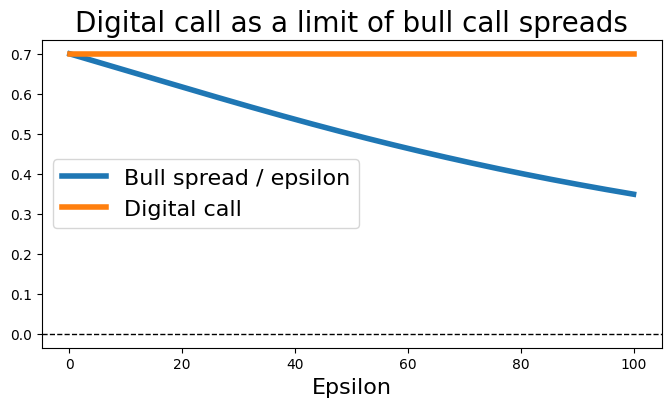

In [23]:
prices_digital = [price_digital] * len(epsilons)

my_plotter(x=epsilons.tolist(), y=[bull_prices, prices_digital],names=["Bull spread / epsilon", "Digital call"],
           layout={"title": "Digital call as a limit of bull call spreads","x_label": "Epsilon"})

#we indeed obtain that, when epsilon tends to 0, the price of the bull spread option divided by epsilon tends to the one of the digital call option. 